In [1]:
!pip install nc_time_axis

In [1]:
import xarray as xr
import nc_time_axis
import PISM

In [2]:
climate_file = "carra2_monthly_mean_RGI2000-v7.0-C-08-00658.nc"
ds = xr.open_dataset(climate_file)
ds_accum = ds.isel(x=1, y=1)

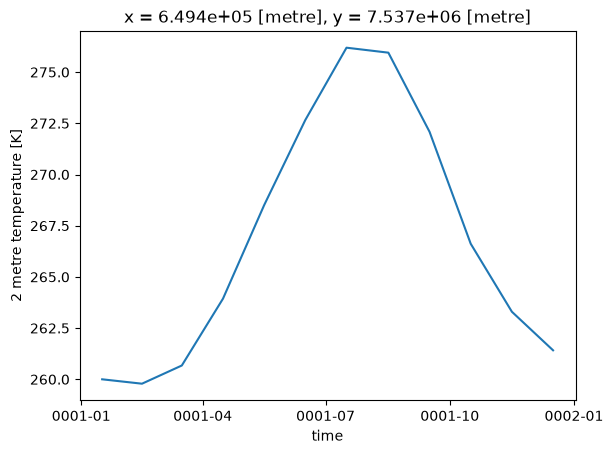

In [3]:
ds_accum.air_temp.plot()

In [4]:
from petsc4py import PETSc

context = PISM.Context()
ctx = context.ctx
config = context.config

PISM.set_abort_on_sigint(True)

In [5]:
registration = PISM.CELL_CENTER
input_filename = "pism_storglaciaren_1994_g10m.nc"

input_file = PISM.File(ctx.com(), input_filename, PISM.PISM_NETCDF3, PISM.PISM_READONLY)
grid = PISM.Grid.FromFile(ctx, input_file, ["thickness"], registration)

In [6]:
PISM.SurfaceTemperatureIndex?

Init signature: PISM.SurfaceTemperatureIndex(g, input)
Docstring:      Proxy of C++ pism::surface::TemperatureIndex class.
Init docstring:
__init__(self, g, input) -> SurfaceTemperatureIndex

Parameters
----------
g: std::shared_ptr< pism::Grid const >
input: std::shared_ptr< pism::atmosphere::AtmosphereModel >
File:           ~/miniforge3/envs/pism-dev/lib/python3.15/site-packages/PISM/cpp.py
Type:           type
Subclasses:     

In [7]:
config.set_string("atmosphere.given.file", climate_file)
config.set_string("atmosphere.elevation_change.file", climate_file)
config.set_string("atmosphere.elevation_change.periodic", "true")
config.set_number("atmosphere.elevation_change.temperature_lapse_rate", 6.0)
config.set_string("atmosphere.given.periodic", "yes")
config.set_string("atmosphere.models", "given,elevation_change")

atmosphere = PISM.AtmosphereGiven(grid)

  - Reading boundary conditions from 'carra2_monthly_mean_RGI2000-v7.0-C-08-00658.nc'...


In [8]:
config.set_string("surface.debm_simple.file", climate_file)
config.set_string("surface.debm_simple.periodic", "yes")
config.set_number("surface.debm_simple.air_temp_all_precip_as_rain", 277.15)
config.set_number("surface.debm_simple.air_temp_all_precip_as_snow", 273.15)
config.set_string("surface.debm_simple.albedo_input.file", climate_file)
config.set_string("surface.debm_simple.albedo_input_file.periodic", "yes")
config.set_string("surface.debm_simple.refreeze_ice_melt", "no")
config.set_string("surface.models", "debem_enhanced")

surface = PISM.SurfaceModel(grid, atmosphere)

In [9]:
config.set_string("time.start", "0001-01-01")
config.set_string("time.end", "0002-01-01")
config.set_string("time.calendar", "365_day")
config.set_string("stress_balance.models", "none")


In [10]:
enthalpyconverter = PISM.EnthalpyConverter(config)

modeldata = PISM.model.ModelData(grid)
modeldata.setPhysics(enthalpyconverter)

vecs = modeldata.vecs

vecs.add(PISM.model.createIceSurfaceVec(grid))
vecs.add(PISM.model.createIceThicknessVec(grid))
vecs.add(PISM.model.createBedrockElevationVec(grid))
vecs.add(PISM.model.createEnthalpyVec(grid))
vecs.add(PISM.model.createIceMaskVec(grid))

# for v in [vecs.thk, vecs.topg, vecs.enthalpy]:
#     v.regrid(input_filename, critical=True)

# variables mask and surface are computed from the geometry previously read
sea_level = PISM.model.createSeaLevelVec(grid)
sea_level.set(0.0)
gc = PISM.GeometryCalculator(config)
gc.compute(sea_level, vecs.topg, vecs.thk, vecs.mask, vecs.surface_altitude)


In [11]:
gc

<PISM.cpp.GeometryCalculator; proxy of <Swig Object of type 'pism::GeometryCalculator *' at 0x32ed893f0> >